<a href="https://colab.research.google.com/github/Rayhwcakep/PCVK/blob/main/week7_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
%%bash
pip install -q pypdf

In [31]:
%%bash
# Menginstal Tesseract OCR dan paket bahasa Indonesia
sudo apt-get update -qq
sudo apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [32]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

# Membaca citra KTP dari user sebagai contoh utama
img_path = '/content/WhatsApp Image 2026-10-12 at 07.38.31.jpeg'
img_color = cv.imread(img_path)
gray_ktp = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

print("Citra KTP berhasil dimuat dengan dimensi:", img_color.shape)

Citra KTP berhasil dimuat dengan dimensi: (458, 694, 3)


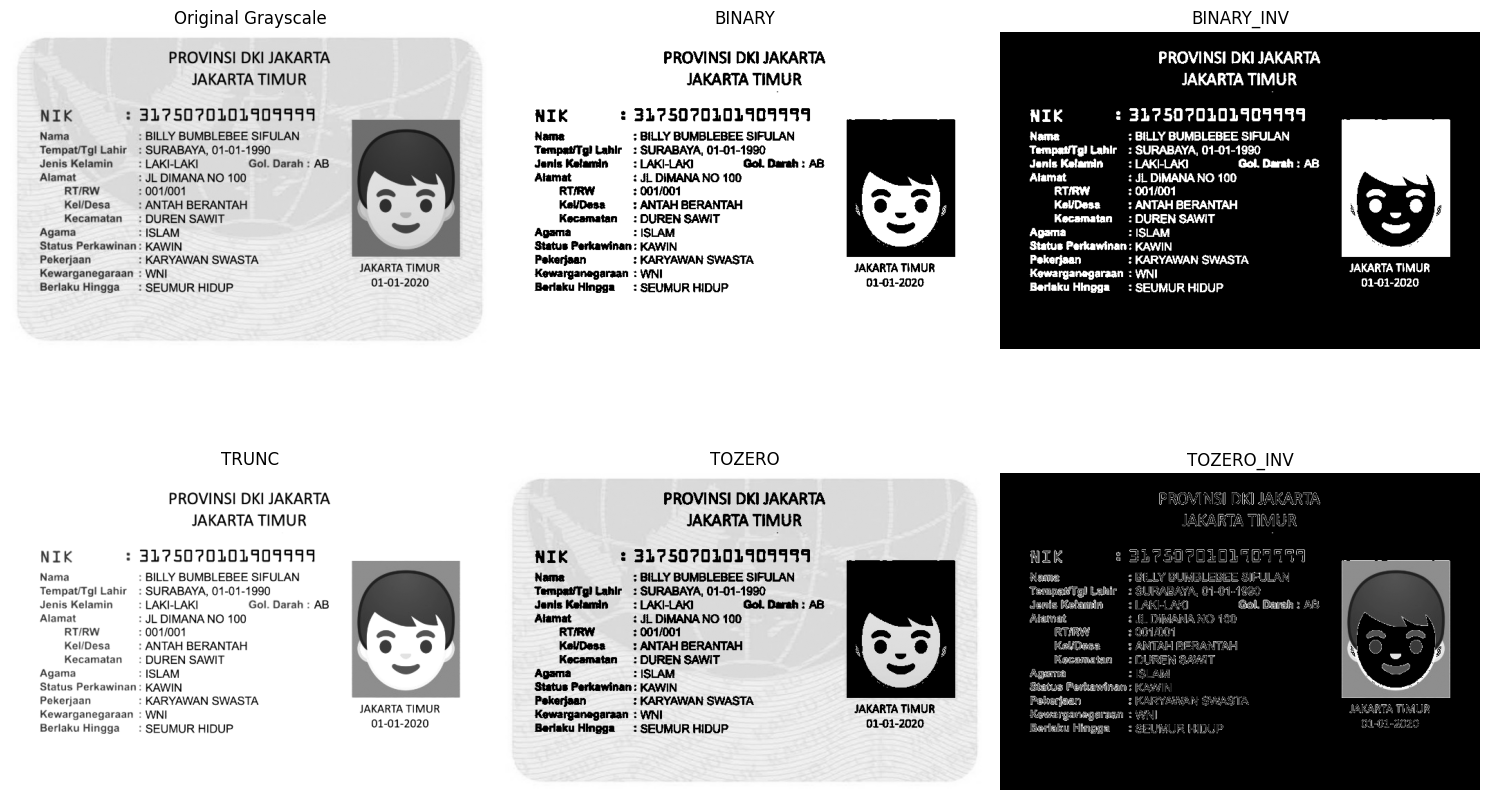

In [33]:
# === TUGAS 3: GLOBAL THRESHOLDING MANUAL (threshold = 200) ===
def manual_global_threshold(img, thresh, max_val=255):
    binary = np.where(img > thresh, max_val, 0).astype(np.uint8)
    binary_inv = np.where(img > thresh, 0, max_val).astype(np.uint8)
    trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
    tozero = np.where(img > thresh, img, 0).astype(np.uint8)
    tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)
    return binary, binary_inv, trunc, tozero, tozero_inv

thresh_val = 200
binary, binary_inv, trunc, tozero, tozero_inv = manual_global_threshold(gray_ktp, thresh_val)

# Plotting Hasil Tugas 3
titles = ['Original Grayscale', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [gray_ktp, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Menghitung manual adaptive mean...
Menghitung manual adaptive gaussian...


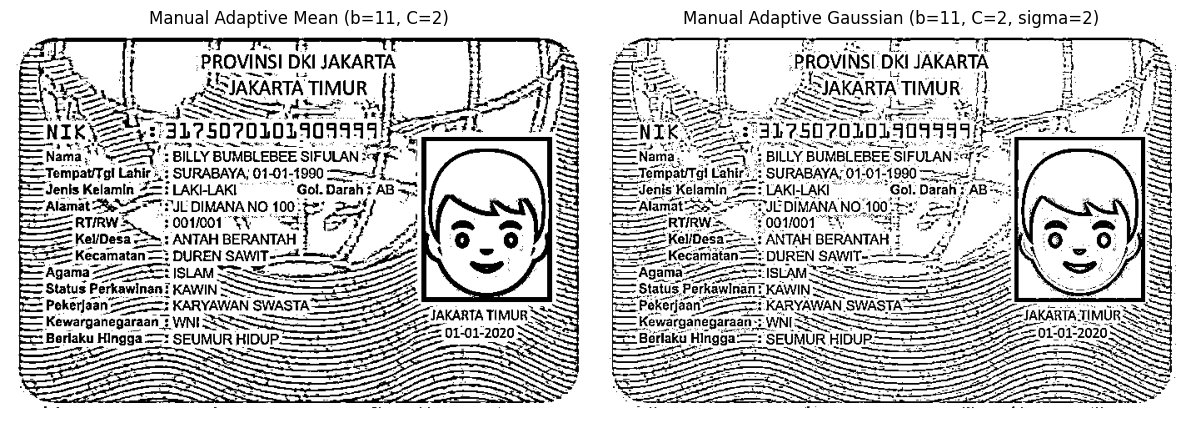

In [34]:
# === TUGAS 4: ADAPTIVE THRESHOLD MANUAL ===
def manual_adaptive_threshold(img, block_size=11, C=2, method='mean', sigma=2):
    h, w = img.shape
    out_img = np.zeros((h, w), dtype=np.uint8)
    half_b = block_size // 2
    padded = np.pad(img, half_b, mode='reflect')

    # Membuat matriks bobot Gaussian secara manual
    if method == 'gaussian':
        x, y = np.mgrid[-half_b:half_b+1, -half_b:half_b+1]
        gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
        gaussian_kernel /= gaussian_kernel.sum()

    for i in range(h):
        for j in range(w):
            # Mengambil area jendela tetangga sekitar piksel
            window = padded[i:i+block_size, j:j+block_size]
            if method == 'mean':
                local_threshold = np.mean(window) - C
            elif method == 'gaussian':
                local_threshold = np.sum(window * gaussian_kernel) - C

            if img[i, j] > local_threshold:
                out_img[i, j] = 255
            else:
                out_img[i, j] = 0
    return out_img

# Uji coba pada citra KTP grayscale
print("Menghitung manual adaptive mean...")
adaptive_mean_manual = manual_adaptive_threshold(gray_ktp, block_size=11, C=2, method='mean')
print("Menghitung manual adaptive gaussian...")
adaptive_gaussian_manual = manual_adaptive_threshold(gray_ktp, block_size=11, C=2, method='gaussian', sigma=2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(adaptive_mean_manual, cmap='gray')
plt.title('Manual Adaptive Mean (b=11, C=2)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(adaptive_gaussian_manual, cmap='gray')
plt.title('Manual Adaptive Gaussian (b=11, C=2, sigma=2)')
plt.axis('off')
plt.tight_layout()
plt.show()

Nilai optimal threshold dari Otsu manual adalah: 151


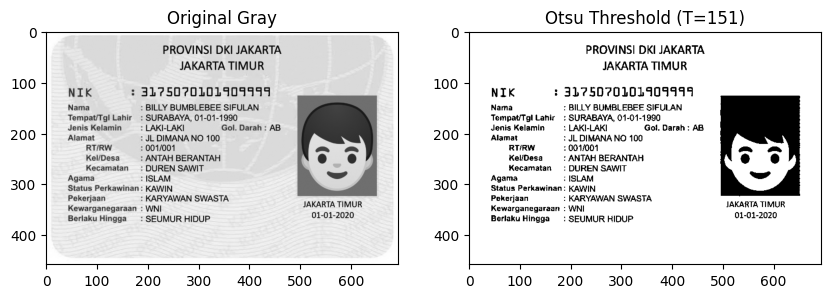

In [35]:
# === TUGAS 5: OTSU THRESHOLD MANUAL ===
def manual_otsu_threshold(img):
    # Hitung histogram
    hist, bins = np.histogram(img.ravel(), bins=256, range=(0, 256))
    total_pixels = img.size

    current_max = -1
    best_threshold = 0

    # Mencari T terbaik yang meminimalkan within-class variance (atau memaksimalkan between-class variance)
    for t in range(1, 256):
        # Background (class 0)
        w0 = np.sum(hist[:t]) / total_pixels
        # Foreground (class 1)
        w1 = np.sum(hist[t:]) / total_pixels

        if w0 == 0 or w1 == 0:
            continue

        # Mean untuk masing-masing kelas
        m0 = np.sum(np.arange(0, t) * hist[:t]) / (np.sum(hist[:t]) or 1)
        m1 = np.sum(np.arange(t, 256) * hist[t:]) / (np.sum(hist[t:]) or 1)

        # Hitung Between-Class Variance
        var_between = w0 * w1 * ((m0 - m1) ** 2)

        if var_between > current_max:
            current_max = var_between
            best_threshold = t

    # Lakukan binarization menggunakan threshold optimal
    binary_otsu = np.where(img > best_threshold, 255, 0).astype(np.uint8)
    return best_threshold, binary_otsu

t_best, otsu_manual_img = manual_otsu_threshold(gray_ktp)
print(f"Nilai optimal threshold dari Otsu manual adalah: {t_best}")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_ktp, cmap='gray')
plt.title('Original Gray')
plt.subplot(1, 2, 2)
plt.imshow(otsu_manual_img, cmap='gray')
plt.title(f"Otsu Threshold (T={t_best})")
plt.show()

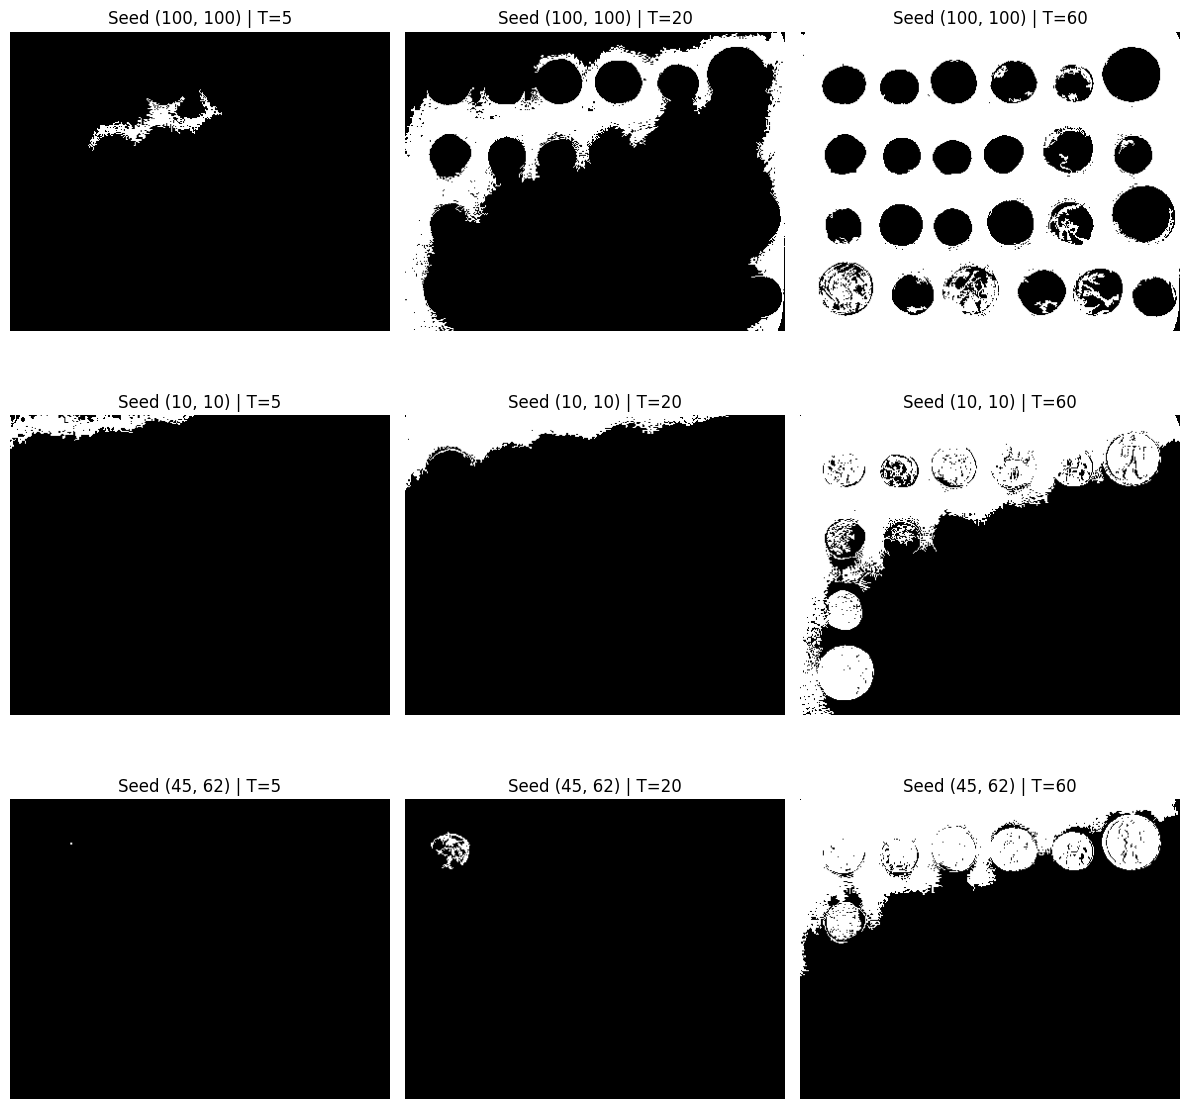

In [36]:
# === TUGAS 6: REGION-BASED SEGMENTATION (COINS) ===
from skimage import data
from skimage.segmentation import flood

coins_img = data.coins()

# Menentukan 3 koordinat seed sesuai ketentuan (di dalam koin, latar, dan tepi koin)
seeds = [
    (100, 100),  # Di dalam koin
    (10, 10),    # Di latar belakang
    (45, 62)     # Di tepi koin
]
tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, seed in enumerate(seeds):
    for j, T in enumerate(tolerances):
        # Segmentasi menggunakan flood fill berdasarkan seed dan toleransi T
        segment_mask = flood(coins_img, seed_point=seed, tolerance=T)

        axes[i, j].imshow(segment_mask, cmap='gray')
        axes[i, j].set_title(f"Seed {seed} | T={T}")
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

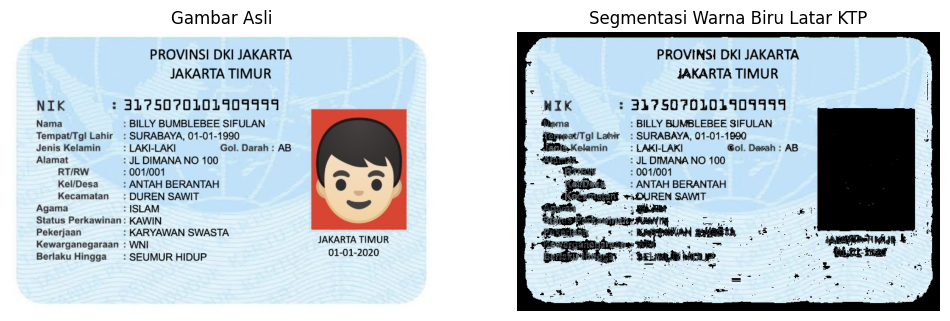

In [37]:
# === TUGAS 7: SEGMENTASI WARNA BIRU LATAR KTP DENGAN K-MEANS ===
img_hsv = cv.cvtColor(img_color, cv.COLOR_BGR2HSV)
H, S, V = cv.split(img_hsv)

# Ambil piksel dengan warna biru sesuai rentang petunjuk modul
blue_mask = np.zeros_like(H)
blue_mask[(H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)] = 255

# Terapkan masking untuk mempertahankan warna asli yang hanya ada di area biru
segmented_blue = cv.bitwise_and(img_color, img_color, mask=blue_mask)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_color, cv.COLOR_BGR2RGB))
plt.title("Gambar Asli")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(segmented_blue, cv.COLOR_BGR2RGB))
plt.title("Segmentasi Warna Biru Latar KTP")
plt.axis('off')
plt.show()

In [38]:
# === TUGAS D2: OCR PERBANDINGAN TULISAN PADA KTP ===
import pytesseract
import pandas as pd

# 1. Siapkan 3 jenis citra masukan
citra_asli = img_color.copy()
_, otsu_bin = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive_bin = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Melakukan pembacaan OCR menggunakan konfigurasi pytesseract bahasa Indonesia
custom_config = r'--oem 3 --psm 6'
txt_asli = pytesseract.image_to_string(citra_asli, lang='ind', config=custom_config)
txt_otsu = pytesseract.image_to_string(otsu_bin, lang='ind', config=custom_config)
txt_adaptive = pytesseract.image_to_string(adaptive_bin, lang='ind', config=custom_config)

print("=== HASIL PEMBACAAN OCR ===")
print("\n--- CITRA ASLI ---\n", txt_asli[:300])
print("\n--- OTSU ---\n", txt_otsu[:300])
print("\n--- ADAPTIVE ---\n", txt_adaptive[:300])

=== HASIL PEMBACAAN OCR ===

--- CITRA ASLI ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkaw

--- OTSU ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan

--- ADAPTIVE ---
 AE: - Hn INN Anna t 5-3
- PROVINSI DKI JAKARTA F Is
Es, N SSJAKARTA TIMUR 14 Hj AS
NIK AS AD 5070100 ANA 1 PL OH
AL an AE tea ” ..
Nama" FAT 4 BILLY BUMBLEBEF SIFULAN $$ "1 .
—TempatTgl Lahir, SURABAYA, 01011900 TSenaad.....€
—Jenis Kelamin #—: LAKI-LAKI “Gol. Darah FAB X7: Kas
Alamat Ss TEULDIMANA 


In [39]:
%%bash
# Menginstal Tesseract OCR dan paket bahasa Indonesia
sudo apt-get update -qq
sudo apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [40]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

# Membaca citra KTP dari user sebagai contoh utama
img_path = '/content/WhatsApp Image 2026-10-12 at 07.38.31.jpeg'
img_color = cv.imread(img_path)
gray_ktp = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

print("Citra KTP berhasil dimuat dengan dimensi:", img_color.shape)

Citra KTP berhasil dimuat dengan dimensi: (458, 694, 3)


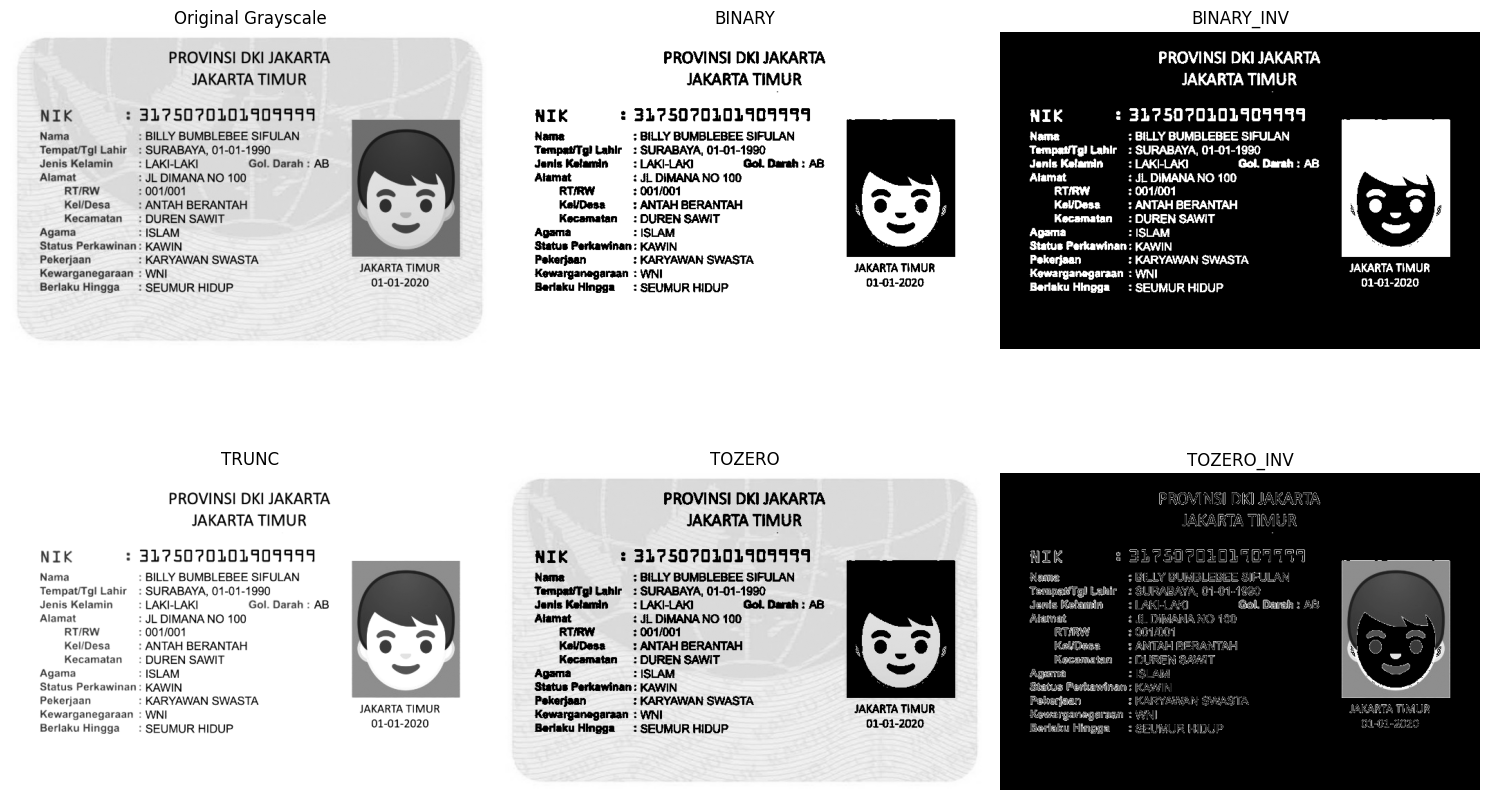

In [41]:
# === TUGAS 3: GLOBAL THRESHOLDING MANUAL (threshold = 200) ===
def manual_global_threshold(img, thresh, max_val=255):
    binary = np.where(img > thresh, max_val, 0).astype(np.uint8)
    binary_inv = np.where(img > thresh, 0, max_val).astype(np.uint8)
    trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
    tozero = np.where(img > thresh, img, 0).astype(np.uint8)
    tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)
    return binary, binary_inv, trunc, tozero, tozero_inv

thresh_val = 200
binary, binary_inv, trunc, tozero, tozero_inv = manual_global_threshold(gray_ktp, thresh_val)

# Plotting Hasil Tugas 3
titles = ['Original Grayscale', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [gray_ktp, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Menghitung manual adaptive mean...
Menghitung manual adaptive gaussian...


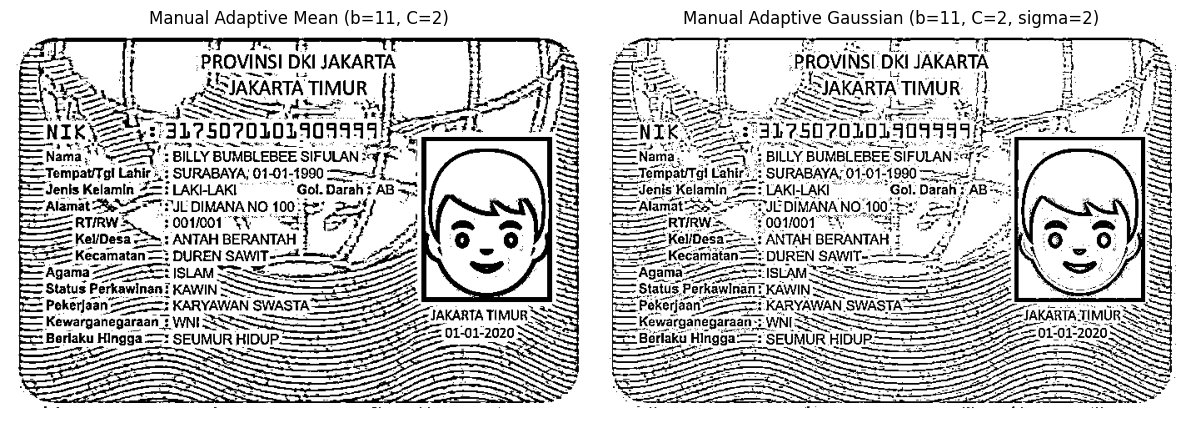

In [42]:
# === TUGAS 4: ADAPTIVE THRESHOLD MANUAL ===
def manual_adaptive_threshold(img, block_size=11, C=2, method='mean', sigma=2):
    h, w = img.shape
    out_img = np.zeros((h, w), dtype=np.uint8)
    half_b = block_size // 2
    padded = np.pad(img, half_b, mode='reflect')

    # Membuat matriks bobot Gaussian secara manual
    if method == 'gaussian':
        x, y = np.mgrid[-half_b:half_b+1, -half_b:half_b+1]
        gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
        gaussian_kernel /= gaussian_kernel.sum()

    for i in range(h):
        for j in range(w):
            # Mengambil area jendela tetangga sekitar piksel
            window = padded[i:i+block_size, j:j+block_size]
            if method == 'mean':
                local_threshold = np.mean(window) - C
            elif method == 'gaussian':
                local_threshold = np.sum(window * gaussian_kernel) - C

            if img[i, j] > local_threshold:
                out_img[i, j] = 255
            else:
                out_img[i, j] = 0
    return out_img

# Uji coba pada citra KTP grayscale
print("Menghitung manual adaptive mean...")
adaptive_mean_manual = manual_adaptive_threshold(gray_ktp, block_size=11, C=2, method='mean')
print("Menghitung manual adaptive gaussian...")
adaptive_gaussian_manual = manual_adaptive_threshold(gray_ktp, block_size=11, C=2, method='gaussian', sigma=2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(adaptive_mean_manual, cmap='gray')
plt.title('Manual Adaptive Mean (b=11, C=2)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(adaptive_gaussian_manual, cmap='gray')
plt.title('Manual Adaptive Gaussian (b=11, C=2, sigma=2)')
plt.axis('off')
plt.tight_layout()
plt.show()

Nilai optimal threshold dari Otsu manual adalah: 151


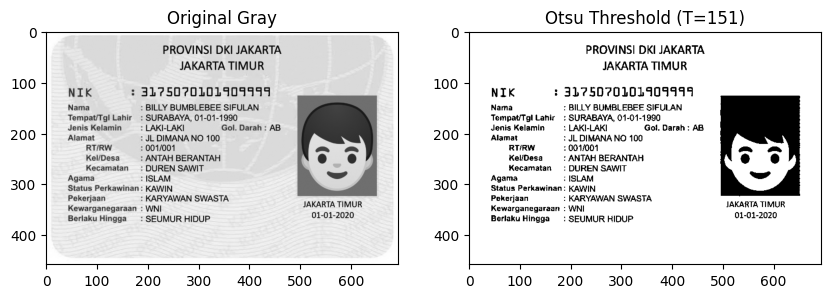

In [43]:
# === TUGAS 5: OTSU THRESHOLD MANUAL ===
def manual_otsu_threshold(img):
    # Hitung histogram
    hist, bins = np.histogram(img.ravel(), bins=256, range=(0, 256))
    total_pixels = img.size

    current_max = -1
    best_threshold = 0

    # Mencari T terbaik yang meminimalkan within-class variance (atau memaksimalkan between-class variance)
    for t in range(1, 256):
        # Background (class 0)
        w0 = np.sum(hist[:t]) / total_pixels
        # Foreground (class 1)
        w1 = np.sum(hist[t:]) / total_pixels

        if w0 == 0 or w1 == 0:
            continue

        # Mean untuk masing-masing kelas
        m0 = np.sum(np.arange(0, t) * hist[:t]) / (np.sum(hist[:t]) or 1)
        m1 = np.sum(np.arange(t, 256) * hist[t:]) / (np.sum(hist[t:]) or 1)

        # Hitung Between-Class Variance
        var_between = w0 * w1 * ((m0 - m1) ** 2)

        if var_between > current_max:
            current_max = var_between
            best_threshold = t

    # Lakukan binarization menggunakan threshold optimal
    binary_otsu = np.where(img > best_threshold, 255, 0).astype(np.uint8)
    return best_threshold, binary_otsu

t_best, otsu_manual_img = manual_otsu_threshold(gray_ktp)
print(f"Nilai optimal threshold dari Otsu manual adalah: {t_best}")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_ktp, cmap='gray')
plt.title('Original Gray')
plt.subplot(1, 2, 2)
plt.imshow(otsu_manual_img, cmap='gray')
plt.title(f"Otsu Threshold (T={t_best})")
plt.show()

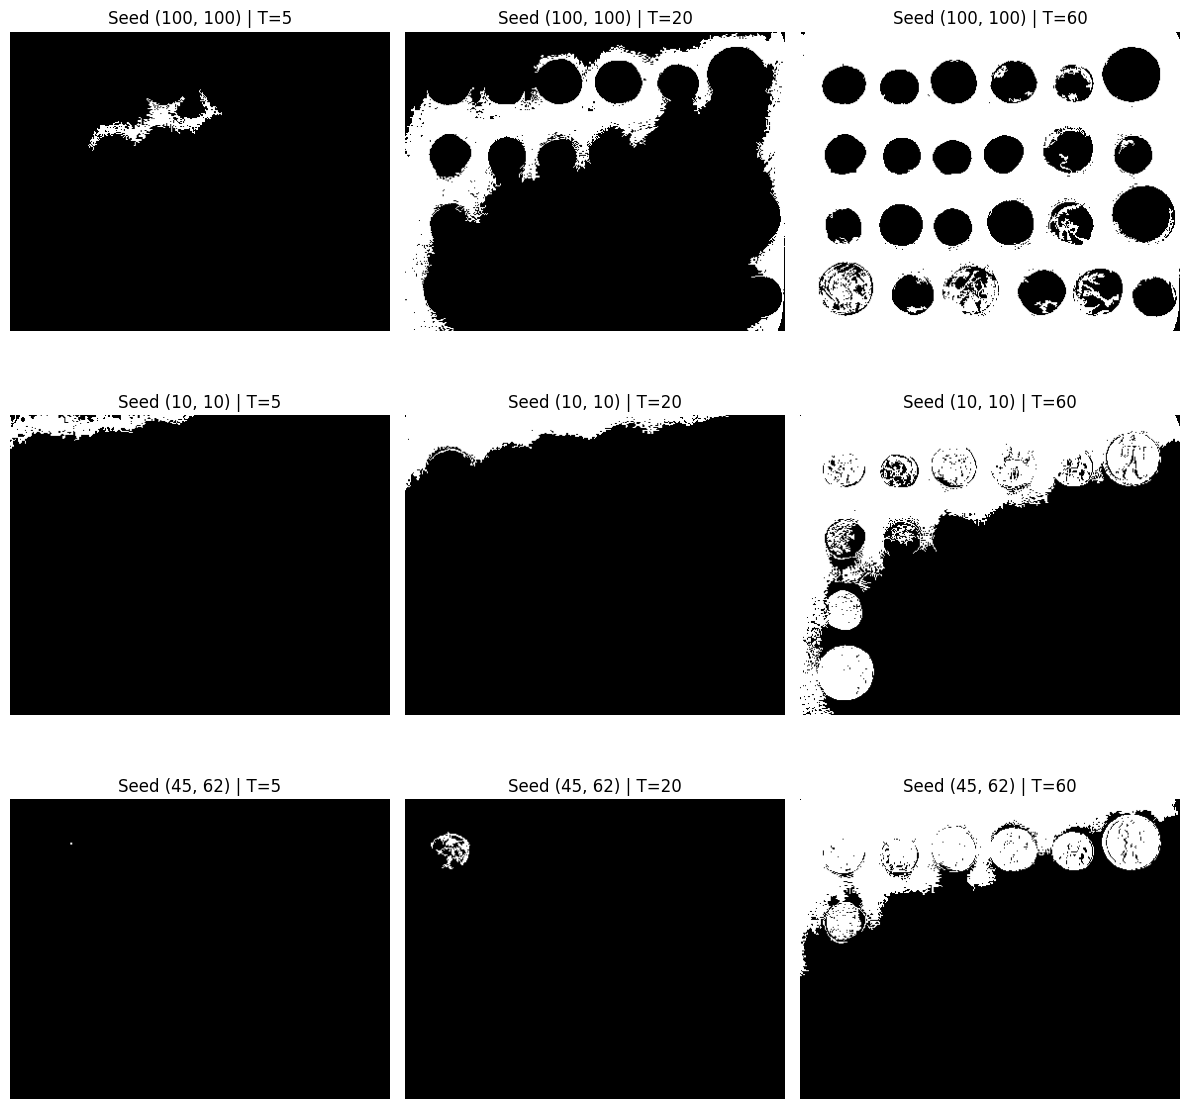

In [44]:
# === TUGAS 6: REGION-BASED SEGMENTATION (COINS) ===
from skimage import data
from skimage.segmentation import flood

coins_img = data.coins()

# Menentukan 3 koordinat seed sesuai ketentuan (di dalam koin, latar, dan tepi koin)
# Anda dapat menyesuaikan titik koordinat ini sesuai sebaran piksel citra coins
seeds = [
    (100, 100),  # Di dalam koin
    (10, 10),    # Di latar belakang
    (45, 62)     # Di tepi koin
]
tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, seed in enumerate(seeds):
    for j, T in enumerate(tolerances):
        # Segmentasi menggunakan flood fill berdasarkan seed dan toleransi T
        segment_mask = flood(coins_img, seed_point=seed, tolerance=T)

        axes[i, j].imshow(segment_mask, cmap='gray')
        axes[i, j].set_title(f"Seed {seed} | T={T}")
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

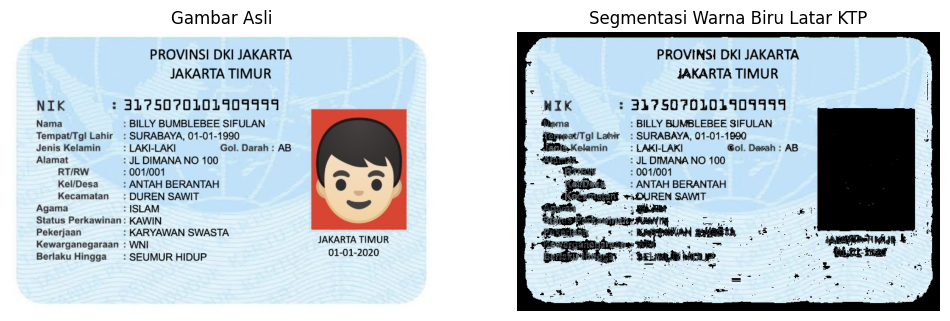

In [45]:
# === TUGAS 7: SEGMENTASI WARNA BIRU LATAR KTP DENGAN K-MEANS ===
img_hsv = cv.cvtColor(img_color, cv.COLOR_BGR2HSV)
H, S, V = cv.split(img_hsv)

# Ambil piksel dengan warna biru sesuai rentang petunjuk modul
blue_mask = np.zeros_like(H)
blue_mask[(H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)] = 255

# Terapkan masking untuk mempertahankan warna asli yang hanya ada di area biru
segmented_blue = cv.bitwise_and(img_color, img_color, mask=blue_mask)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_color, cv.COLOR_BGR2RGB))

plt.title("Gambar Asli")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(segmented_blue, cv.COLOR_BGR2RGB))

plt.title("Segmentasi Warna Biru Latar KTP")
plt.axis('off')
plt.show()

In [46]:
# === TUGAS D2: OCR PERBANDINGAN TULISAN PADA KTP ===
import pytesseract
import pandas as pd

# 1. Siapkan 3 jenis citra masukan
citra_asli = img_color.copy()
_, otsu_bin = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive_bin = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Melakukan pembacaan OCR menggunakan konfigurasi pytesseract bahasa Indonesia
custom_config = r'--oem 3 --psm 6'
txt_asli = pytesseract.image_to_string(citra_asli, lang='ind', config=custom_config)
txt_otsu = pytesseract.image_to_string(otsu_bin, lang='ind', config=custom_config)
txt_adaptive = pytesseract.image_to_string(adaptive_bin, lang='ind', config=custom_config)

print("=== HASIL PEMBACAAN OCR ===")
print("\n--- CITRA ASLI ---\n", txt_asli[:300])
print("\n--- OTSU ---\n", txt_otsu[:300])
print("\n--- ADAPTIVE ---\n", txt_adaptive[:300])

=== HASIL PEMBACAAN OCR ===

--- CITRA ASLI ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkaw

--- OTSU ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan

--- ADAPTIVE ---
 AE: - Hn INN Anna t 5-3
- PROVINSI DKI JAKARTA F Is
Es, N SSJAKARTA TIMUR 14 Hj AS
NIK AS AD 5070100 ANA 1 PL OH
AL an AE tea ” ..
Nama" FAT 4 BILLY BUMBLEBEF SIFULAN $$ "1 .
—TempatTgl Lahir, SURABAYA, 01011900 TSenaad.....€
—Jenis Kelamin #—: LAKI-LAKI “Gol. Darah FAB X7: Kas
Alamat Ss TEULDIMANA 
